# Day-ahead demand forecast, chosen with walk-forward validation (Phase 3, step 3c)

**What this notebook does.** It forecasts how many Uber/Lyft requests each of the 263 NYC taxi zones gets in each clock hour (our stand-in for robotaxi demand), using only information that is known at least **7 days** before the forecast hour. It is the same task as `03b_forecast_with_lags.ipynb`, but the forecast method is **chosen with seven walk-forward folds instead of one September validation month**.

**Why it exists.** Demand differs between months (about ±8% in level, about 12% higher in rainy hours, higher on holidays). September-October, the old validation period, was an easy and almost rain-free stretch: October had rain in 0.1% of its hours. One validation period of two months is too little evidence for choosing settings. The reason and the numbers are recorded in `docs/decisions.md` ("Walk-forward validation instead of one Sep-Oct validation", pending team review).

**The new design.**
1. Seven folds inside January-October: train on January-March and validate on April, then train on January-April and validate on May, and so on, up to train on January-September and validate on October. A fold never trains on a month at or after the month it is scored on.
2. Four gradient boosting settings and four simple baselines are scored in every fold. We compare them by **WAPE** (total absolute error divided by total actual requests, in percent), so busy months do not count more than quiet ones.
3. The best model is chosen only if it beats the best baseline on average **and** in at least 5 of the 7 folds. Otherwise the simple baseline wins. This rule is written before any fold score is seen.
4. The choice is saved, the best setting is refitted on all of January-October, and only then are November-December and January 2025 read. November-December was already examined in older experiments, so its scores are labelled *previously examined, not a pristine test*. January 2025 gets predictions only (for the later drift check).

**What is not here.** No weather or rain input (that is a separate step), no count-bias scale (the old Oct 1-15 scale was dropped because the folds replace it), and the month number is still a model input for now.

**Terms.** *Lag* = the count from the same zone and clock hour 7 / 14 / 21 / 28 days earlier. *MAE* = average absolute error in requests per zone-hour. *Frozen profile* = a fixed table of the average demand of each zone, weekday and hour over the last 28 (or 7) days before training ended; it is never updated. *Baseline* = a simple rule that needs no model.

**Last full run:** see the final code cell, which prints the run time.

## Step 1. Set up: paths, settings and constants

All dates, seeds and model settings are named constants in this one cell, so nothing is hidden further down. The repository root is found by walking up to the folder that holds `repo_instructions.md`, so no personal path is typed in. Outputs go to `data/forecasts_walk_forward/`, so the 03b forecast file stays untouched.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
                  if (folder / "repo_instructions.md").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT))

In [2]:
import json
import time
import warnings
from datetime import UTC, datetime
from importlib import metadata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from src.demand_features import (
    CIVIL_KEY,
    MIN_FOLD_WINS,
    PRETEST_MONTHS,
    add_baseline_columns,
    build_features,
    build_frozen_profiles,
    choose_method_from_folds,
    list_feature_columns,
    make_civil_hour_table,
    make_walk_forward_folds,
    mark_common_rows,
    score_by_group,
    score_forecast,
)

warnings.filterwarnings("ignore", message=".*IProgress.*")
RUN_STARTED_UTC = datetime.now(UTC)
RANDOM_SEED = 20261115
OCTOBER_START = "2024-10-01"        # October forecasts come from the model trained on Jan-Sep
FINAL_TRAIN_END = "2024-11-01"      # final model trains on Jan-Oct (end date not included)
TEST_END = "2025-01-01"             # test = Nov-Dec (previously examined)
FORECAST_START = "2024-10-01"       # forecast file starts here
DRIFT_END = "2025-02-01"            # January 2025 is predicted for later drift use
SHAP_SAMPLE_ROWS = 5000
PERMUTATION_REPEATS = 3
QUARTILE_LABELS = ["Low", "Lower-middle", "Upper-middle", "High"]
RELEASE_DIR = REPO_ROOT / "data/releases/phase1-2024-v1"
FORECAST_DIR = REPO_ROOT / "data/forecasts_walk_forward"
FORECAST_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_COLUMNS = ["pred_last_week", "pred_four_week_mean", "pred_frozen_profile", "pred_frozen_profile_7d"]
BASELINE_NAMES = {
    "pred_last_week": "Last week (lag_7d)",
    "pred_four_week_mean": "Mean of previous 4 weeks",
    "pred_frozen_profile": "Frozen 28-day profile",
    "pred_frozen_profile_7d": "Frozen 7-day profile",
}

# Four small candidate settings, the same four as in 03b, written down before any score was seen.
CANDIDATE_SETTINGS = {
    "hgb_squared_small": {"loss": "squared_error", "learning_rate": 0.1, "max_iter": 200,
                          "max_leaf_nodes": 15, "min_samples_leaf": 200},
    "hgb_squared_large": {"loss": "squared_error", "learning_rate": 0.05, "max_iter": 400,
                          "max_leaf_nodes": 31, "min_samples_leaf": 100},
    "hgb_poisson_small": {"loss": "poisson", "learning_rate": 0.1, "max_iter": 200,
                          "max_leaf_nodes": 15, "min_samples_leaf": 200},
    "hgb_poisson_large": {"loss": "poisson", "learning_rate": 0.05, "max_iter": 400,
                          "max_leaf_nodes": 31, "min_samples_leaf": 100},
}
CANDIDATE_NAMES = list(CANDIDATE_SETTINGS)
BASELINE_DISPLAY_NAMES = list(BASELINE_NAMES.values())
ALL_METHOD_NAMES = CANDIDATE_NAMES + BASELINE_DISPLAY_NAMES
plt.rcParams.update({"figure.dpi": 100, "axes.spines.right": False, "axes.spines.top": False})
print("Repository root found; forecast outputs go to", FORECAST_DIR.relative_to(REPO_ROOT))

Matplotlib is building the font cache; this may take a moment.


Repository root found; forecast outputs go to data\forecasts_walk_forward


## Step 2. Load January-October only (train and validation)

We read the Phase 1 hourly table with `pyarrow`. At this stage we load **only the train and validation periods**; November-December labels are not read until the final choice is saved. We also load the zone table (borough, centroid, airport flag). `request_count` is null when coverage was incomplete; we never turn a null into zero. We also read the observed-rain flag of the main weather station, **only to report scores for rainy hours**; it is not a model input. A missing rain flag is treated as "no rain" and the number of such hours is printed.

In [3]:
table_index = json.loads((RELEASE_DIR / "metadata/table_index.json").read_text(encoding="utf-8"))
zone_hour_dataset = ds.dataset(REPO_ROOT / table_index["zone_hour"]["path"], format="parquet", partitioning="hive")
ZONE_HOUR_COLUMNS = ["zone_id", "hour_start_utc", "event_date_nyc", "hour_nyc", "period_label",
                     "request_count", "is_federal_holiday", "has_observed_rain"]


def read_zone_hours(period_labels):
    """Read the hourly zone table for the given period labels (train, validation, ...)."""
    rows = zone_hour_dataset.to_table(
        columns=ZONE_HOUR_COLUMNS, filter=ds.field("period_label").isin(period_labels)).to_pandas()
    rows["event_date_nyc"] = pd.to_datetime(rows["event_date_nyc"])
    unknown_rain_hours = int(rows["has_observed_rain"].isna().sum())
    rows["has_observed_rain"] = rows["has_observed_rain"].fillna(False).astype(bool)
    print(f"Read {len(rows):,} zone-hour rows for {period_labels}; rain flag missing in {unknown_rain_hours:,} (treated as no rain)")
    return rows


pretest_rows = read_zone_hours(["train", "validation"])
zones = ds.dataset(REPO_ROOT / table_index["zones"]["path"], format="parquet").to_table(
    columns=["zone_id", "borough", "is_airport", "centroid_latitude", "centroid_longitude"]).to_pandas()
BOROUGHS = sorted(zones["borough"].unique())
print("Zones:", len(zones), "| boroughs:", BOROUGHS)
print("Latest day loaded:", pretest_rows["event_date_nyc"].max().date())
print("Null request counts in train+validation:", int(pretest_rows["request_count"].isna().sum()))
assert pretest_rows["event_date_nyc"].max() < pd.Timestamp(FINAL_TRAIN_END)
assert len(zones) == 263 and zones["zone_id"].is_unique

Read 1,924,897 zone-hour rows for ['train', 'validation']; rain flag missing in 1,696,350 (treated as no rain)
Zones: 263 | boroughs: ['Bronx', 'Brooklyn', 'EWR', 'Manhattan', 'Queens', 'Staten Island']
Latest day loaded: 2024-10-31
Null request counts in train+validation: 0


## Step 3. Civil-time key and lag features

Lags are defined on **New York civil time**: "same weekday and same clock hour, 7 days earlier". We therefore key every row by `(zone_id, event_date_nyc, hour_nyc)`. On the autumn clock-change day the clock hour 1 happens twice; those two rows share one civil key, so they are averaged (and stay null if either count is null). Then `build_features` adds the calendar inputs, zone geography, the four lags, their mean (only when at least 2 lags exist) and a ratio of last week to that mean. No weather, fares or any other outcome is used as a model input. Each row also gets its `event_month` (a text like `2024-04`), which the folds use to decide who trains and who is scored.

In [4]:
def make_rainy_hour_table(zone_hour_rows):
    """Return one row per New York date and clock hour: is_rainy_hour = rain observed at the main station."""
    rows = zone_hour_rows[["event_date_nyc", "hour_nyc", "has_observed_rain"]]
    rainy_hours = rows.groupby(["event_date_nyc", "hour_nyc"], as_index=False)["has_observed_rain"].any()
    return rainy_hours.rename(columns={"has_observed_rain": "is_rainy_hour"})


civil_pretest = make_civil_hour_table(pretest_rows)
features_pretest = build_features(civil_pretest, zones, BOROUGHS)
features_pretest["event_month"] = features_pretest["event_date_nyc"].dt.strftime("%Y-%m")
FEATURE_COLUMNS = list_feature_columns(BOROUGHS)
rainy_hours_pretest = make_rainy_hour_table(pretest_rows)
print("Number of model inputs:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)
print("Months present:", sorted(features_pretest["event_month"].unique()))

Civil hour table: 1,924,897 zone-hour rows -> 1,924,897 civil rows


Lag features added: 1,924,897 rows


Geography added: 1,924,897 rows


Number of model inputs: 28
['hour', 'weekday', 'month', 'is_weekend', 'is_federal_holiday', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'centroid_latitude', 'centroid_longitude', 'is_airport', 'borough_Bronx', 'borough_Brooklyn', 'borough_EWR', 'borough_Manhattan', 'borough_Queens', 'borough_Staten Island', 'lag_7d', 'lag_14d', 'lag_21d', 'lag_28d', 'lag_7d_is_holiday', 'lag_14d_is_holiday', 'lag_21d_is_holiday', 'lag_28d_is_holiday', 'lag_mean_4w', 'lag_7d_ratio']
Months present: ['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10']


## Step 4. The seven walk-forward folds

`make_walk_forward_folds` (in `src/demand_features.py`, tested) returns one fold for each month from April to October. In each fold the training months are every month before the validation month. The table shows the folds. November and December appear nowhere in it.

In [5]:
folds = make_walk_forward_folds(PRETEST_MONTHS)
display(pd.DataFrame({
    "fold": range(1, len(folds) + 1),
    "trains on": [f"{fold['train_months'][0]} to {fold['train_months'][-1]}" for fold in folds],
    "scored on": [fold["validation_month"] for fold in folds],
}).set_index("fold"))
assert all(max(fold["train_months"]) < fold["validation_month"] for fold in folds)

,trains on,scored on
fold,,
1,2024-01 to 2024-03,2024-04
2,2024-01 to 2024-04,2024-05
3,2024-01 to 2024-05,2024-06
4,2024-01 to 2024-06,2024-07
5,2024-01 to 2024-07,2024-08
6,2024-01 to 2024-08,2024-09
7,2024-01 to 2024-09,2024-10


## Step 5. Fit four candidates in every fold and score them against the baselines

`HistGradientBoostingRegressor` is scikit-learn's fast gradient boosting. It accepts missing lags directly, so rows from the first weeks of January (when lags do not exist yet) stay in training. Early stopping is switched off and the random seed is fixed, so a rerun gives the same model. The four candidates differ in loss (squared error versus Poisson, which suits counts) and size.

In every fold:
* the candidates are fitted on the training months only;
* the **frozen profiles are rebuilt from days before the validation month**, so a profile never contains the month it is scored on;
* every method is scored on the **identical rows** of the validation month: rows with a known actual count, all four lags and both frozen profiles;
* the lags of a validation day are real counts from at least 7 days earlier, which a dispatcher would have a week ahead. No model setting is learned from the validation month.

In [6]:
def fit_candidate(settings, training_table):
    """Fit one gradient boosting model on the training rows and return it."""
    model = HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_SEED, **settings)
    return model.fit(training_table[FEATURE_COLUMNS], training_table["request_count"])


def predict_counts(model, table):
    """Predict requests per zone-hour and clip impossible negative values to zero."""
    return np.maximum(model.predict(table[FEATURE_COLUMNS]), 0.0)


fold_score_records = []
fold_coverage_records = []
fold_prediction_frames = []
last_fold_models = {}
for fold in folds:
    fold_started = time.time()
    validation_month = fold["validation_month"]
    train_rows = features_pretest[features_pretest["event_month"].isin(fold["train_months"])
                                  & features_pretest["request_count"].notna()]
    month_rows = features_pretest[features_pretest["event_month"] == validation_month]
    fold_profiles = build_frozen_profiles(civil_pretest, f"{validation_month}-01")
    month_rows = add_baseline_columns(month_rows, fold_profiles)
    month_rows["is_common_row"] = mark_common_rows(month_rows, BASELINE_COLUMNS)
    scored_rows = month_rows[month_rows["is_common_row"]].copy()

    method_predictions = {}
    for candidate_name, settings in CANDIDATE_SETTINGS.items():
        fitted_model = fit_candidate(settings, train_rows)
        method_predictions[candidate_name] = predict_counts(fitted_model, scored_rows)
        if fold == folds[-1]:
            last_fold_models[candidate_name] = fitted_model
    for column, name in BASELINE_NAMES.items():
        method_predictions[name] = scored_rows[column].to_numpy()
    if fold == folds[-1]:
        last_fold_profiles = fold_profiles

    for method_name, predicted in method_predictions.items():
        fold_score_records.append({"fold": validation_month, "method": method_name,
                                   **score_forecast(scored_rows["request_count"], predicted)})
    prediction_frame = scored_rows[["event_date_nyc", "hour_nyc", "request_count", "is_federal_holiday"]].copy()
    prediction_frame["fold"] = validation_month
    for method_name, predicted in method_predictions.items():
        prediction_frame[method_name] = predicted
    fold_prediction_frames.append(prediction_frame)
    fold_coverage_records.append({"fold": validation_month, "training_rows": len(train_rows),
                                  "month_rows": len(month_rows), "scored_rows": len(scored_rows),
                                  "seconds": round(time.time() - fold_started, 1)})
    print(f"Fold {validation_month}: trained on {len(train_rows):,} rows, scored {len(scored_rows):,} rows, "
          f"{time.time() - fold_started:.0f} s")

display(pd.DataFrame(fold_coverage_records).set_index("fold"))

Baselines added: 189,360 rows


Fold 2024-04: trained on 574,129 rows, scored 188,308 rows, 32 s


Baselines added: 195,672 rows


Fold 2024-05: trained on 763,489 rows, scored 195,672 rows, 39 s


Baselines added: 189,360 rows


Fold 2024-06: trained on 959,161 rows, scored 189,360 rows, 53 s


... (5 outputs left out)

Fold 2024-09: trained on 1,539,865 rows, scored 189,360 rows, 87 s


Baselines added: 195,672 rows


Fold 2024-10: trained on 1,729,225 rows, scored 195,672 rows, 90 s


,training_rows,month_rows,scored_rows,seconds
fold,,,,
2024-04,574129,189360,188308,32.1
2024-05,763489,195672,195672,39.0
2024-06,959161,189360,189360,53.3
2024-07,1148521,195672,195672,71.6
2024-08,1344193,195672,195672,75.1
2024-09,1539865,189360,189360,86.5
2024-10,1729225,195672,195672,90.1


## Step 6. Scores in every fold, and in rainy and holiday hours

The first table is WAPE (percent, lower is better): one row per method, one column per fold. The second is MAE in requests per zone-hour. Below them, the folds are pooled to show how every method does in **rainy hours** and on **federal holidays**. These two breakdowns are for information; they do not decide the winner, because each fold has only a few rainy hours.

In [7]:
fold_scores = pd.DataFrame(fold_score_records)
wape_by_fold = fold_scores.pivot(index="method", columns="fold", values="WAPE_percent").loc[ALL_METHOD_NAMES]
mae_by_fold = fold_scores.pivot(index="method", columns="fold", values="MAE").loc[ALL_METHOD_NAMES]
print("WAPE (%) by fold")
display(wape_by_fold.round(2).assign(mean=wape_by_fold.mean(axis=1).round(2)))
print("MAE (requests per zone-hour) by fold")
display(mae_by_fold.round(2).assign(mean=mae_by_fold.mean(axis=1).round(2)))

pooled_folds = pd.concat(fold_prediction_frames, ignore_index=True)
pooled_folds = pooled_folds.merge(rainy_hours_pretest, on=["event_date_nyc", "hour_nyc"], how="left", validate="many_to_one")
pooled_folds["weather_group"] = np.where(pooled_folds["is_rainy_hour"].fillna(False), "Rain", "No rain")
pooled_folds["holiday_group"] = np.where(pooled_folds["is_federal_holiday"] > 0, "Federal holiday", "Normal day")
print("Pooled over all seven folds (WAPE %):")
for group_column in ["weather_group", "holiday_group"]:
    group_scores = score_by_group(pooled_folds, group_column, ALL_METHOD_NAMES)
    counts = pooled_folds.groupby(group_column).size().rename("rows")
    table = group_scores.pivot(index=group_column, columns="method", values="WAPE_percent")[ALL_METHOD_NAMES].round(2)
    display(table.join(counts))

WAPE (%) by fold


fold,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,mean
method,,,,,,,,
hgb_squared_small,13.60,13.63,13.18,15.44,13.11,14.94,12.88,13.83
hgb_squared_large,13.61,13.59,13.15,15.34,13.04,14.97,12.88,13.80
hgb_poisson_small,13.51,13.66,13.08,15.41,13.03,15.04,12.91,13.81
hgb_poisson_large,13.45,13.56,13.01,15.30,12.98,14.99,12.97,13.75
Last week (lag_7d),16.08,16.25,17.18,19.34,15.45,16.61,15.01,16.56
Mean of previous 4 weeks,13.17,13.59,13.20,15.60,13.62,14.77,12.13,13.72
Frozen 28-day profile,13.64,13.74,13.46,16.07,14.12,15.83,12.57,14.21
Frozen 7-day profile,16.47,17.16,19.96,18.72,15.78,18.84,16.17,17.59


MAE (requests per zone-hour) by fold


fold,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,mean
method,,,,,,,,
hgb_squared_small,14.04,14.29,13.87,14.99,12.69,15.01,13.04,13.99
hgb_squared_large,14.06,14.24,13.84,14.89,12.62,15.04,13.04,13.96
hgb_poisson_small,13.95,14.32,13.77,14.95,12.62,15.10,13.08,13.97
hgb_poisson_large,13.90,14.22,13.70,14.85,12.57,15.05,13.13,13.92
Last week (lag_7d),16.60,17.04,18.08,18.77,14.96,16.68,15.20,16.76
Mean of previous 4 weeks,13.61,14.24,13.89,15.14,13.19,14.83,12.28,13.88
Frozen 28-day profile,14.09,14.41,14.17,15.60,13.67,15.90,12.73,14.37
Frozen 7-day profile,17.01,17.99,21.01,18.17,15.27,18.92,16.37,17.82


Pooled over all seven folds (WAPE %):


,hgb_squared_small,hgb_squared_large,hgb_poisson_small,hgb_poisson_large,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile,rows
weather_group,,,,,,,,,
No rain,13.59,13.55,13.57,13.51,16.41,13.52,13.99,17.42,1271605
Rain,17.12,17.21,17.10,17.10,18.54,16.46,17.06,20.04,78111


,hgb_squared_small,hgb_squared_large,hgb_poisson_small,hgb_poisson_large,Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile,rows
holiday_group,,,,,,,,,
Federal holiday,25.73,25.18,25.62,24.76,32.79,32.20,32.17,33.01,31560
Normal day,13.57,13.55,13.55,13.52,16.22,13.33,13.82,17.27,1318156


## Step 7. Choose the method with the rule written in advance

`choose_method_from_folds` (tested) takes the WAPE table above. The best model is the candidate with the lowest average WAPE; the best baseline likewise. **The model is chosen only if its average is lower than the best baseline's and it beats that baseline in at least 5 of the 7 folds.** Otherwise the simple baseline wins: if a complicated model cannot clearly beat a simple rule, we use the simple rule. The worst fold of the chosen method is printed so a bad month cannot hide behind a good average.

Best model setting: hgb_poisson_large (mean WAPE 13.75%)
Best baseline:      Mean of previous 4 weeks (mean WAPE 13.72%)
Model beats that baseline in 4 of 7 folds (needs 5).
CHOSEN METHOD: Mean of previous 4 weeks; its worst fold is 2024-07 with WAPE 15.60%.


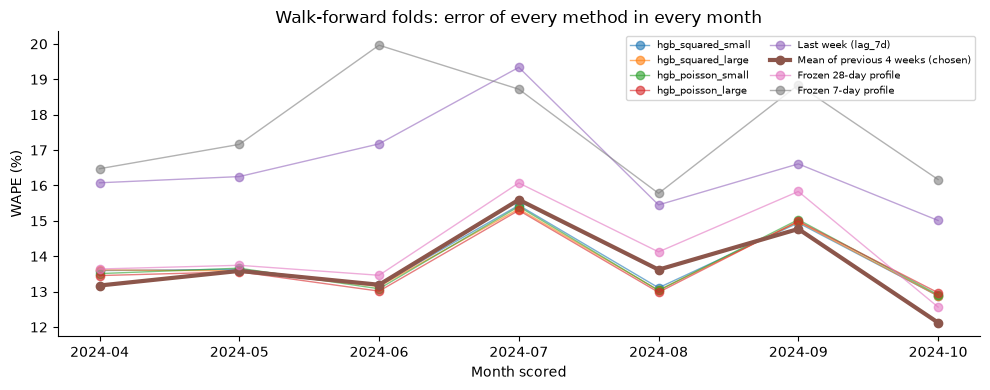

In [8]:
choice = choose_method_from_folds(wape_by_fold, CANDIDATE_NAMES, BASELINE_DISPLAY_NAMES, MIN_FOLD_WINS)
best_candidate = choice["best_model"]
final_method = choice["chosen"]
if choice["model_is_chosen"]:
    final_method_column = "pred_model"
else:
    final_method_column = next(column for column, name in BASELINE_NAMES.items() if name == final_method)
print(f"Best model setting: {choice['best_model']} (mean WAPE {choice['mean_wape'][choice['best_model']]:.2f}%)")
print(f"Best baseline:      {choice['best_baseline']} (mean WAPE {choice['mean_wape'][choice['best_baseline']]:.2f}%)")
print(f"Model beats that baseline in {choice['folds_model_wins']} of {choice['number_of_folds']} folds "
      f"(needs {choice['min_fold_wins']}).")
print(f"CHOSEN METHOD: {final_method}; its worst fold is {choice['worst_fold']} with WAPE {choice['worst_fold_wape']:.2f}%.")

fig, axis = plt.subplots(figsize=(10, 4))
for method_name in ALL_METHOD_NAMES:
    is_chosen = method_name == final_method
    axis.plot(wape_by_fold.columns, wape_by_fold.loc[method_name], marker="o", linewidth=3 if is_chosen else 1,
              alpha=1 if is_chosen else 0.6, label=method_name + (" (chosen)" if is_chosen else ""))
axis.set(xlabel="Month scored", ylabel="WAPE (%)", title="Walk-forward folds: error of every method in every month")
axis.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## Step 8. Save the frozen choice, refit on January-October, **before** reading November-December

From here nothing about the choice changes. The best model setting is refitted on **all** of January-October (the final model). The October forecasts will come from the last fold's model, trained on January-September, because the final model has already seen October's real counts and would look unfairly good there; later phases and the drift check treat October as honest. The choice, settings, fold scores and date windows are written to `data/forecasts_walk_forward/frozen_choice.json` and both models are saved. Only after this file exists does the notebook load the test and drift periods.

In [9]:
final_train_rows = features_pretest[features_pretest["request_count"].notna()]
final_model = fit_candidate(CANDIDATE_SETTINGS[best_candidate], final_train_rows)
october_model = last_fold_models[best_candidate]
print(f"Final model fitted on {len(final_train_rows):,} January-October rows")

frozen_choice = {
    "saved_at_utc": datetime.now(UTC).isoformat(),
    "nov_dec_labels_read_before_this_file_was_saved": False,
    "random_seed": RANDOM_SEED,
    "walk_forward_folds": folds,
    "min_fold_wins": MIN_FOLD_WINS,
    "windows": {"final_training": ["2024-01-01", FINAL_TRAIN_END],
                "october_forecasts_from_model_trained_on": ["2024-01-01", OCTOBER_START],
                "test_nov_dec_previously_examined": [FINAL_TRAIN_END, TEST_END]},
    "candidate_settings": CANDIDATE_SETTINGS,
    "fold_scores": fold_scores.to_dict(orient="records"),
    "choice": choice,
    "chosen_candidate": best_candidate,
    "chosen_settings": CANDIDATE_SETTINGS[best_candidate],
    "best_method": final_method,
    "best_method_column_in_forecast_file": final_method_column,
    "count_bias_scale": "dropped (the folds replace the old Oct 1-15 scale)",
    "feature_columns": FEATURE_COLUMNS,
}
choice_path = FORECAST_DIR / "frozen_choice.json"
choice_path.write_text(json.dumps(frozen_choice, indent=2, allow_nan=False), encoding="utf-8")
joblib.dump(final_model, FORECAST_DIR / "frozen_model.joblib")
joblib.dump(october_model, FORECAST_DIR / "october_model_trained_jan_sep.joblib")
print("Saved", choice_path.relative_to(REPO_ROOT), "and both model files")

Final model fitted on 1,924,897 January-October rows


Saved data\forecasts_walk_forward\frozen_choice.json and both model files


## Step 9. Load November-December and January 2025; rebuild features on the full table

Now the later periods are read. Their counts serve two purposes: (a) labels for scoring November-December, and (b) lag inputs for target hours at least 7 days later (a count from 1 November is a legitimate lag for 8 November). January 2025 is used for predictions only. As a safety check we confirm that adding later months did not change a single feature value of the October rows, which shows that lags only look backwards.

In [10]:
later_rows = read_zone_hours(["test", "drift"])
all_rows = pd.concat([pretest_rows, later_rows], ignore_index=True)
print(f"All zone-hour rows: {len(all_rows):,}")
civil_all = make_civil_hour_table(all_rows)
features_all = build_features(civil_all, zones, BOROUGHS)
features_all["event_month"] = features_all["event_date_nyc"].dt.strftime("%Y-%m")
rainy_hours_all = make_rainy_hour_table(all_rows)

october_before = features_pretest[features_pretest["event_month"] == "2024-10"]
october_after = features_all[features_all["event_month"] == "2024-10"]
pd.testing.assert_frame_equal(october_before[CIVIL_KEY + FEATURE_COLUMNS].reset_index(drop=True),
                              october_after[CIVIL_KEY + FEATURE_COLUMNS].reset_index(drop=True))
print("PASS: later months did not change any October feature (lags only look back).")

Read 580,967 zone-hour rows for ['test', 'drift']; rain flag missing in 510,220 (treated as no rain)


All zone-hour rows: 2,505,864


Civil hour table: 2,505,864 zone-hour rows -> 2,505,601 civil rows


Lag features added: 2,505,601 rows


Geography added: 2,505,601 rows


PASS: later months did not change any October feature (lags only look back).


## Step 10. Predict every zone-hour from 1 October 2024 to 31 January 2025

October rows are predicted by the model trained on January-September, with frozen profiles built from days before 1 October. November-January rows are predicted by the final model (January-October), with frozen profiles built from days before 1 November. The baselines and the model come from the same feature table. Predictions are one per civil key; the repeated clock-change hour gets the same prediction for both of its real UTC hours.

In [11]:
october_features = features_all[features_all["event_month"] == "2024-10"].copy()
later_features = features_all[(features_all["event_date_nyc"] >= pd.Timestamp(FINAL_TRAIN_END))
                              & (features_all["event_date_nyc"] < pd.Timestamp(DRIFT_END))].copy()
forecast_pieces = []
for piece, profile_end_date, model in [(october_features, OCTOBER_START, october_model),
                                       (later_features, FINAL_TRAIN_END, final_model)]:
    piece_profiles = build_frozen_profiles(civil_all, profile_end_date)
    if profile_end_date == OCTOBER_START:
        pd.testing.assert_frame_equal(piece_profiles, last_fold_profiles)
    piece = add_baseline_columns(piece, piece_profiles)
    piece["is_common_row"] = mark_common_rows(piece, BASELINE_COLUMNS)
    piece["pred_model"] = predict_counts(model, piece)
    forecast_pieces.append(piece)
forecast_table = pd.concat(forecast_pieces, ignore_index=True)
forecast_table["is_scored_row"] = forecast_table["is_common_row"]
print(f"Forecast rows (civil keys): {len(forecast_table):,}")
print(forecast_table.groupby("period_label")["is_scored_row"].agg(["size", "sum"]))

Baselines added: 195,672 rows


Baselines added: 580,704 rows


Forecast rows (civil keys): 776,376
                size     sum
period_label                
drift         195672  195672
test          385032  383717
validation    195672  195672


## Step 11. Score November-December (previously examined period, not a pristine test)

All methods are scored on the **identical rows** (actual known, four lags known, frozen profiles known). The choice among methods was fixed in Step 8 and is not changed after seeing these numbers. MAE and RMSE are in requests per zone-hour; WAPE is a percentage.

Nov-Dec rows: 385,032 | actual known: 384,769 | identical scored rows: 383,717
PREVIOUSLY EXAMINED PERIOD - not a pristine test


,rows,MAE,RMSE,WAPE_percent
"Best model setting (hgb_poisson_large), refit on Jan-Oct",383717,18.860403,40.137567,17.917168
Last week (lag_7d),383717,23.107360,49.439793,21.951729
Mean of previous 4 weeks,383717,19.213401,40.898773,18.252512
Frozen 28-day profile,383717,19.882255,42.144545,18.887916
Frozen 7-day profile,383717,22.895282,49.605687,21.750258


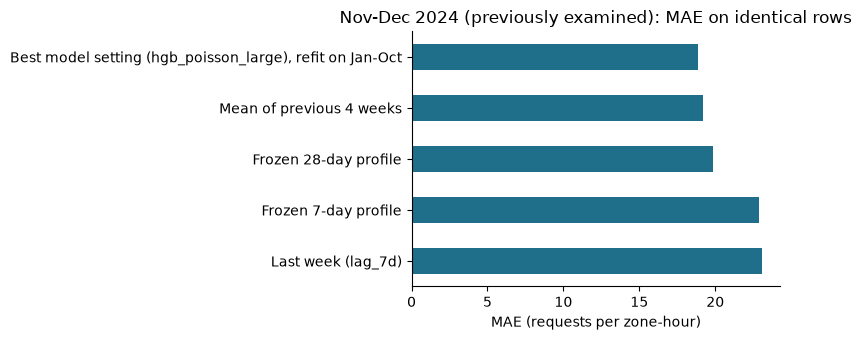

Method frozen on the seven folds: Mean of previous 4 weeks -> Nov-Dec MAE 19.213 (best model setting: 18.860)
The model can also forecast rows lacking some lags: MAE on all 384,769 rows with a known actual = 18.893


In [12]:
METHOD_COLUMNS = {"pred_model": f"Best model setting ({best_candidate}), refit on Jan-Oct",
                  **BASELINE_NAMES}
test_rows = forecast_table[(forecast_table["event_date_nyc"] >= pd.Timestamp(FINAL_TRAIN_END))
                           & (forecast_table["event_date_nyc"] < pd.Timestamp(TEST_END))]
test_scored = test_rows[test_rows["is_scored_row"]].copy()
print(f"Nov-Dec rows: {len(test_rows):,} | actual known: {int(test_rows['request_count'].notna().sum()):,} "
      f"| identical scored rows: {len(test_scored):,}")
overall_scores = pd.DataFrame({name: score_forecast(test_scored["request_count"], test_scored[column])
                               for column, name in METHOD_COLUMNS.items()}).T
overall_scores["rows"] = overall_scores["rows"].astype(int)
print("PREVIOUSLY EXAMINED PERIOD - not a pristine test")
display(overall_scores)

fig, axis = plt.subplots(figsize=(8, 3.5))
overall_scores["MAE"].sort_values(ascending=False).plot.barh(ax=axis, color="#1f6f8b")
axis.set(xlabel="MAE (requests per zone-hour)", ylabel="",
         title="Nov-Dec 2024 (previously examined): MAE on identical rows")
plt.tight_layout()
plt.show()

frozen_choice_mae = overall_scores.loc[METHOD_COLUMNS[final_method_column], "MAE"]
print(f"Method frozen on the seven folds: {final_method} -> Nov-Dec MAE {frozen_choice_mae:.3f} "
      f"(best model setting: {overall_scores.loc[METHOD_COLUMNS['pred_model'], 'MAE']:.3f})")

model_all_rows = test_rows[test_rows["request_count"].notna()]
scores_all_known_rows = score_forecast(model_all_rows["request_count"], model_all_rows["pred_model"])
print(f"The model can also forecast rows lacking some lags: MAE on all {scores_all_known_rows['rows']:,} "
      f"rows with a known actual = {scores_all_known_rows['MAE']:.3f}")

## Step 12. Where is the forecast good or bad? (Nov-Dec, previously examined)

The same identical rows are broken down by month, by clock hour, by federal holiday versus normal day, by observed rain versus no rain, and by a zone's **training demand quartile** (zones ranked by their average January-October demand, split into four equal groups of zones). These tables describe weaknesses; they are not used to change the model.

In [13]:
method_columns = list(METHOD_COLUMNS)
test_scored["month"] = test_scored["event_date_nyc"].dt.strftime("%Y-%m")
test_scored["holiday_group"] = np.where(test_scored["is_federal_holiday"] > 0, "Federal holiday", "Normal day")
test_scored = test_scored.merge(rainy_hours_all, on=["event_date_nyc", "hour_nyc"], how="left", validate="many_to_one")
test_scored["weather_group"] = np.where(test_scored["is_rainy_hour"].fillna(False), "Rain", "No rain")
zone_training_demand = final_train_rows.groupby("zone_id")["request_count"].mean()
zone_quartile = pd.qcut(zone_training_demand.rank(method="first"), 4, labels=QUARTILE_LABELS)
test_scored["training_demand_quartile"] = test_scored["zone_id"].map(zone_quartile)

breakdowns = {}
for group_column in ["month", "holiday_group", "weather_group", "training_demand_quartile"]:
    long_scores = score_by_group(test_scored, group_column, method_columns)
    breakdowns[group_column] = long_scores
    print(f"--- by {group_column}")
    display(long_scores.pivot(index=group_column, columns="method", values="MAE").round(2)[method_columns]
            .rename(columns=METHOD_COLUMNS))
    display(long_scores.pivot(index=group_column, columns="method", values="WAPE_percent").round(2)[method_columns]
            .rename(columns=METHOD_COLUMNS))
hour_scores = score_by_group(test_scored, "hour_nyc", method_columns)
breakdowns["hour_nyc"] = hour_scores

--- by month


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
month,,,,,
2024-11,16.53,20.18,16.78,16.81,20.32
2024-12,21.10,25.93,21.56,22.85,25.38


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
month,,,,,
2024-11,15.87,19.37,16.11,16.14,19.51
2024-12,19.85,24.39,20.27,21.49,23.87


--- by holiday_group


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
holiday_group,,,,,
Federal holiday,31.54,40.47,37.21,36.14,35.17
Normal day,18.20,22.21,18.28,19.04,22.26


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
holiday_group,,,,,
Federal holiday,35.87,46.02,42.31,41.09,39.99
Normal day,17.15,20.92,17.22,17.93,20.97


... (2 outputs left out)

method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
weather_group,,,,,
No rain,17.60,21.86,17.84,18.28,21.27
Rain,20.76,22.75,21.93,24.35,26.04


--- by training_demand_quartile


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
training_demand_quartile,,,,,
High,41.83,51.07,42.48,42.90,49.63
Low,3.81,4.63,3.86,4.21,5.01
Lower-middle,10.82,13.41,11.04,11.86,13.40
Upper-middle,18.98,23.32,19.48,20.57,23.56


method,"Best model setting (hgb_poisson_large), refit on Jan-Oct",Last week (lag_7d),Mean of previous 4 weeks,Frozen 28-day profile,Frozen 7-day profile
training_demand_quartile,,,,,
High,18.14,22.15,18.42,18.60,21.52
Low,25.45,30.97,25.76,28.16,33.45
Lower-middle,17.90,22.17,18.25,19.61,22.16
Upper-middle,16.48,20.25,16.92,17.86,20.46


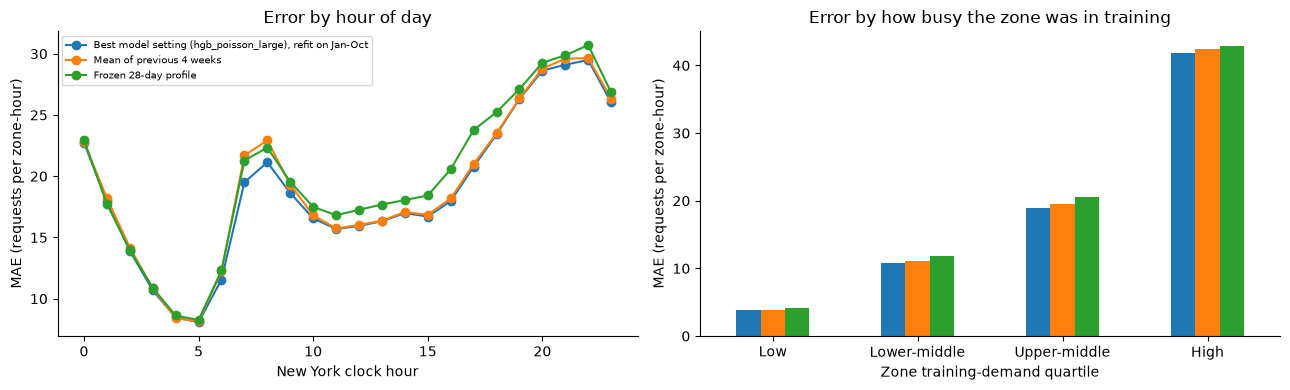

Days on which the model has lower MAE than the 4-week mean: 35 of 61


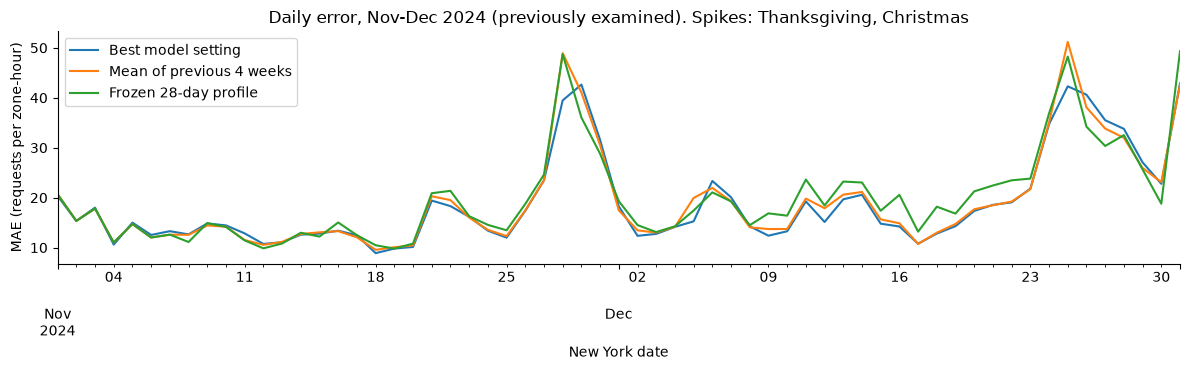

In [14]:
hour_mae = hour_scores.pivot(index="hour_nyc", columns="method", values="MAE")
quartile_mae = breakdowns["training_demand_quartile"].pivot(
    index="training_demand_quartile", columns="method", values="MAE").loc[QUARTILE_LABELS]
shown_methods = ["pred_model", "pred_four_week_mean", "pred_frozen_profile"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column in shown_methods:
    axes[0].plot(hour_mae.index, hour_mae[column], marker="o", label=METHOD_COLUMNS[column])
axes[0].set(xlabel="New York clock hour", ylabel="MAE (requests per zone-hour)", title="Error by hour of day")
axes[0].legend(fontsize=7)
quartile_mae[shown_methods].rename(columns=METHOD_COLUMNS).plot.bar(ax=axes[1], rot=0, legend=False)
axes[1].set(xlabel="Zone training-demand quartile", ylabel="MAE (requests per zone-hour)",
            title="Error by how busy the zone was in training")
plt.tight_layout()
plt.show()

daily_errors = test_scored.assign(
    error_model=(test_scored["pred_model"] - test_scored["request_count"]).abs(),
    error_four_week=(test_scored["pred_four_week_mean"] - test_scored["request_count"]).abs(),
    error_frozen=(test_scored["pred_frozen_profile"] - test_scored["request_count"]).abs())
daily_mae = daily_errors.groupby("event_date_nyc")[["error_model", "error_four_week", "error_frozen"]].mean()
daily_mae.columns = ["Best model setting", "Mean of previous 4 weeks", "Frozen 28-day profile"]
days_model_is_better = int((daily_mae["Best model setting"] < daily_mae["Mean of previous 4 weeks"]).sum())
print(f"Days on which the model has lower MAE than the 4-week mean: {days_model_is_better} of {len(daily_mae)}")
daily_mae.plot(figsize=(12, 3.8), ylabel="MAE (requests per zone-hour)", xlabel="New York date",
               title="Daily error, Nov-Dec 2024 (previously examined). Spikes: Thanksgiving, Christmas")
plt.tight_layout()
plt.show()

## Step 13. Which inputs does the October model use?

We explain the October model (trained on January-September) on a random sample of 5,000 of its **October scoring rows**, which were not in its training data. If the `shap` package is installed, **SHAP** shares each forecast out among the inputs: for every row it says how many requests each input pushed the forecast up or down. If not, the cell falls back to scikit-learn's permutation importance (how much MAE grows when one input is shuffled) and says so. **Importance is not causation**: it describes how this model uses its inputs, not what would happen if we changed them. Correlated inputs (for example the four lags) split the credit between them.

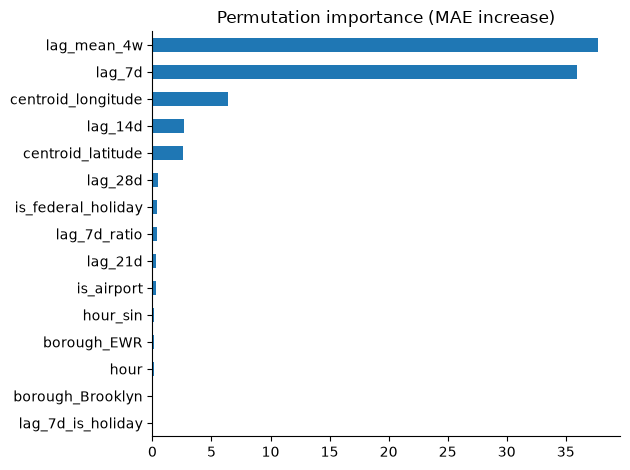

Explanation method used: permutation importance (shap could not be imported: No module named 'shap')


,mean_abs_importance
lag_mean_4w,37.705809
lag_7d,35.940707
centroid_longitude,6.434062
lag_14d,2.702734
centroid_latitude,2.587564
lag_28d,0.436999
is_federal_holiday,0.405754
lag_7d_ratio,0.395367
lag_21d,0.265830
is_airport,0.264902


In [15]:
october_scored = forecast_table[(forecast_table["event_month"] == "2024-10") & forecast_table["is_scored_row"]]
explain_rows = october_scored.sample(n=SHAP_SAMPLE_ROWS, random_state=RANDOM_SEED)
explain_inputs = explain_rows[FEATURE_COLUMNS]
try:
    import shap
    explanation_method = "SHAP (TreeExplainer)"
    shap_values = shap.TreeExplainer(october_model).shap_values(explain_inputs)
    importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURE_COLUMNS)
    shap.summary_plot(shap_values, explain_inputs, show=False, max_display=15)
    plt.title("SHAP summary: October model, 5,000 October rows")
    plt.tight_layout()
    plt.show()
except ImportError as import_error:
    explanation_method = "permutation importance (shap could not be imported: " + str(import_error) + ")"
    result = permutation_importance(
        october_model, explain_inputs, explain_rows["request_count"], scoring="neg_mean_absolute_error",
        n_repeats=PERMUTATION_REPEATS, random_state=RANDOM_SEED)
    importance = pd.Series(result.importances_mean, index=FEATURE_COLUMNS)
    importance.sort_values().tail(15).plot.barh(title="Permutation importance (MAE increase)")
    plt.tight_layout()
    plt.show()
print("Explanation method used:", explanation_method)
importance_table = importance.sort_values(ascending=False).rename("mean_abs_importance").to_frame()
display(importance_table.head(12))

## Step 14. Save the forecast file and the summary

`forecast_zone_hour.parquet` has one row per real zone-hour from 2024-10-01 to 2025-01-31, with the same columns as the 03b file. `pred_model` is the best model setting (October from the January-September model, later months from the January-October model). `pred_frozen_profile` is the 28-day profile; the 7-day profile is an extra column. A prediction is empty where a baseline cannot be computed. `is_scored_row` is true for the identical rows used for scoring. The summary JSON holds every metric, setting, seed, row count and package version.

In [16]:
real_hours = all_rows[(all_rows["event_date_nyc"] >= pd.Timestamp(FORECAST_START))
                      & (all_rows["event_date_nyc"] < pd.Timestamp(DRIFT_END))]
prediction_columns = CIVIL_KEY + ["pred_model", "pred_last_week", "pred_four_week_mean",
                                  "pred_frozen_profile", "pred_frozen_profile_7d", "is_scored_row"]
forecast_file = real_hours[["zone_id", "hour_start_utc", "event_date_nyc", "hour_nyc",
                            "period_label", "request_count"]].merge(
    forecast_table[prediction_columns], on=CIVIL_KEY, how="left", validate="many_to_one")
forecast_file["event_date_nyc"] = forecast_file["event_date_nyc"].dt.date
print(f"Forecast file rows: {len(forecast_file):,} (source real-hour rows: {len(real_hours):,})")
assert len(forecast_file) == len(real_hours)
assert not forecast_file.duplicated(["zone_id", "hour_start_utc"]).any()
assert forecast_file["pred_model"].notna().all() and (forecast_file["pred_model"] >= 0).all()
assert forecast_file["is_scored_row"].notna().all()

forecast_path = FORECAST_DIR / "forecast_zone_hour.parquet"
forecast_file.to_parquet(forecast_path, index=False)
saved_file = pd.read_parquet(forecast_path)
check = saved_file.groupby("period_label").agg(
    rows=("zone_id", "size"), actual_known=("request_count", "count"), scored=("is_scored_row", "sum"))
assert len(saved_file) == len(forecast_file)
display(check)

Forecast file rows: 776,639 (source real-hour rows: 776,639)


,rows,actual_known,scored
period_label,,,
drift,195672,195672,195672
test,385295,384769,383717
validation,195672,195672,195672


In [17]:
def get_package_version(package_name):
    """Return the installed version of a package, or a clear message if it is missing."""
    try:
        return metadata.version(package_name)
    except metadata.PackageNotFoundError:
        return "not installed"


scored_by_period = check["scored"].astype(int).to_dict()
summary = {
    "created_at_utc": datetime.now(UTC).isoformat(),
    "run_started_utc": RUN_STARTED_UTC.isoformat(),
    "nov_dec_status": "previously examined period, not a pristine test",
    "january_2025_status": "predictions only, never scored, fitted or used for selection",
    "seeds": {"random_seed": RANDOM_SEED},
    "row_counts": {
        "final_training_rows": len(final_train_rows),
        "fold_coverage": fold_coverage_records,
        "nov_dec_rows": len(test_rows),
        "nov_dec_identical_scored_rows": len(test_scored),
        "forecast_file_rows": len(forecast_file),
        "scored_rows_by_period": scored_by_period,
    },
    "walk_forward_folds": folds,
    "choice": choice,
    "chosen_settings": frozen_choice["chosen_settings"],
    "chosen_candidate": best_candidate,
    "best_method": final_method,
    "best_method_column_in_forecast_file": final_method_column,
    "fold_scores": fold_scores.to_dict(orient="records"),
    "nov_dec_mae_of_method_frozen_on_the_folds": float(frozen_choice_mae),
    "nov_dec_days_model_beats_four_week_mean": days_model_is_better,
    "nov_dec_overall_scores": overall_scores.reset_index(names="method").to_dict(orient="records"),
    "nov_dec_model_on_all_rows_with_actual": scores_all_known_rows,
    "nov_dec_by_group": {name: scores.to_dict(orient="records") for name, scores in breakdowns.items()},
    "pooled_fold_scores_by_group": {
        group: score_by_group(pooled_folds, group, ALL_METHOD_NAMES).to_dict(orient="records")
        for group in ["weather_group", "holiday_group"]},
    "explanation_method": explanation_method,
    "feature_importance_top15": importance_table.head(15)["mean_abs_importance"].to_dict(),
    "package_versions": {name: get_package_version(name) for name in
                         ["scikit-learn", "numpy", "pandas", "pyarrow", "shap", "matplotlib", "joblib"]},
}
summary_path = FORECAST_DIR / "forecast_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8")
print("Saved", summary_path.relative_to(REPO_ROOT))
print("Run finished at", datetime.now(UTC).isoformat(), "| started", RUN_STARTED_UTC.isoformat())

Saved data\forecasts_walk_forward\forecast_summary.json
Run finished at 2026-11-15T22:23:32.990792+00:00 | started 2026-11-15T22:14:33.780834+00:00


## Step 15. What this result does and does not say

* The forecast uses only counts at least 7 days old, plus calendar and zone geography, so it can be produced a day (or a week) ahead.
* The method was chosen on seven walk-forward folds (April-October), each trained only on earlier months, with a rule written before any score was seen. The count-bias scale of 03b was dropped.
* November-December labels were seen in older experiments, so those scores are **diagnostic, not a pristine test**. January 2025 was not scored here.
* The October forecasts come from a model that never saw October. Later months come from the model refitted on January-October.
* The rain flag was used only to *report* scores in rainy hours. It is not a model input, and the raw month number is still an input; whether to change either is a separate step.
* Forecast accuracy alone does not prove a better fleet placement or more profit; that needs the fleet simulation, and Phases 4-7 have **not** been re-run on this forecast file.
* Weak spots to keep in mind: public holidays (Thanksgiving and Christmas never appear in the folds), very quiet zones (small counts make percentage errors large) and the busiest zones (large absolute errors).